# Khmer word detection v2 (fine-tune)
Continues from v1 (`~/khmer-models/khmer_word_det/weights/best.pt`) and trains on **old synthetic data + your real data**.
Put real data on the school machine as `data/real/images/*.png` + `data/real/labels/*.txt` (YOLO format, class 0), e.g. via the Jupyter upload button.

In [2]:
import os, subprocess
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)

Sun Nov  8 00:59:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4090        On  |   00000000:01:00.0  On |                  Off |
|  0%   41C    P8             32W /  515W |    4877MiB /  24564MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
%pip install -q ultralytics kagglehub

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch; assert torch.cuda.is_available(), 'no CUDA'; print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 4090


## Data: old (same split as v1) + real

In [5]:
import os, random, shutil, yaml
from pathlib import Path
import kagglehub

def put(a, b):
    b.parent.mkdir(parents=True, exist_ok=True)
    if not b.exists():
        try: os.link(a, b)
        except OSError: shutil.copy2(a, b)

def split(img_dir, lab_dir, out, seed=0):
    stems = sorted(p.stem for p in Path(img_dir).glob('*.png') if (Path(lab_dir)/f'{p.stem}.txt').exists())
    random.Random(seed).shuffle(stems)
    n = len(stems)
    cut = {'train': stems[:int(.8*n)], 'val': stems[int(.8*n):int(.9*n)], 'test': stems[int(.9*n):]}
    for k, ss in cut.items():
        for s in ss:
            put(Path(img_dir)/f'{s}.png', out/'images'/k/f'{s}.png')
            put(Path(lab_dir)/f'{s}.txt', out/'labels'/k/f'{s}.txt')
    return {k: len(v) for k, v in cut.items()}

src = Path(kagglehub.dataset_download('emhengly/khmer-text-detection-dataset'))
OLD = Path('khmer-det').resolve()      # same seed/split as v1, so the old test set stays unseen
print('old :', split(src/'PNG_Files'/'PNG_Files', src/'labels_yolov8_format'/'labels_yolov8_format', OLD))

REAL_KAGGLE = 'chimixx/khmer-detection'   # already split: khmer-detection_{train,val,test}/khmer-detection/{images,labels}
real_src = Path(kagglehub.dataset_download(REAL_KAGGLE))
REAL = {k: next(real_src.rglob(f'khmer-detection_{k}'))/'khmer-detection' for k in ('train', 'val', 'test')}
print('real:', {k: len(list((v/'images'/k).glob('*'))) for k, v in REAL.items()})

def yml(path, **kw):
    Path(path).write_text(yaml.safe_dump({'names': {0: 'khmer_word'}, **kw}, sort_keys=False)); return str(Path(path).resolve())
DATA_MIX  = yml('data_v2.yaml',   train=[str(OLD/'images/train'), str(REAL['train']/'images'/'train')], val=[str(OLD/'images/val'), str(REAL['val']/'images'/'val')])
DATA_OLD  = yml('data_old_test.yaml',  train=str(OLD/'images/train'), val=str(OLD/'images/test'))
DATA_REAL = yml('data_real_test.yaml', train=str(REAL['train']/'images'/'train'), val=str(REAL['test']/'images'/'test'))

old : {'train': 8040, 'val': 1005, 'test': 1005}
real: {'train': 1600, 'val': 200, 'test': 200}


## Train (fine-tune from v1 weights)
Lower learning rate than v1. Raise `EPOCHS` if real-data mAP is still rising.

In [6]:
from ultralytics import YOLO
V1 = Path.home()/'khmer-models/khmer_word_det/weights/best.pt'
assert V1.exists(), f'missing {V1}'
EPOCHS, IMGSZ, BATCH = 30, 640, 24
OUT_DIR = Path.home()/'khmer-models'
RUN = OUT_DIR/'khmer_word_det_v2'
BEST, LAST = RUN/'weights/best.pt', RUN/'weights/last.pt'

if LAST.exists():
    try: YOLO(LAST).train(resume=True)
    except Exception as e: print('nothing to resume:', e)
else:
    YOLO(V1).train(data=DATA_MIX, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=0,
                   project=str(OUT_DIR), name='khmer_word_det_v2', exist_ok=True,
                   optimizer='SGD', lr0=0.002, warmup_epochs=1, patience=10, save_period=5)
print(BEST, BEST.exists())

New https://pypi.org/project/ultralytics/8.4.205 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.107 🚀 Python-3.13.11 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 24078MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/vila/data_v2.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

## Validate: old test vs real test (v1 vs v2)

In [7]:
def score(w, data):
    m = YOLO(w).val(data=data, split='val', imgsz=IMGSZ, iou=0.5, verbose=False)
    return f'P={m.box.mp:.3f} R={m.box.mr:.3f} mAP50={m.box.map50:.3f} mAP50-95={m.box.map:.3f}'
for name, w in [('v1', V1), ('v2', BEST)]:
    print(name, 'old test :', score(w, DATA_OLD))
    print(name, 'real test:', score(w, DATA_REAL))

Ultralytics 8.4.107 🚀 Python-3.13.11 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 24078MiB)
Model summary (fused): 113 layers, 43,607,379 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 141.6±43.7 MB/s, size: 62.5 KB)
val: Scanning /home/vila/khmer-det/labels/test.cache... 1005 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1005/1005 702.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 8.1it/s 7.8s0.1ss
                   all       1005     112929      0.991      0.991      0.993      0.983
Speed: 0.5ms preprocess, 4.7ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/vila/runs/detect/val-2
v1 old test : P=0.991 R=0.991 mAP50=0.993 mAP50-95=0.983
Ultralytics 8.4.107 🚀 Python-3.13.11 torch-2.13.0+cu130 CUDA:0 (NVIDIA GeForce RTX 4090, 24078MiB)
Model summary (fused): 113 layers, 43,607,379 parameters, 0 gradients, 164.8 GFLOPs
val: Fa

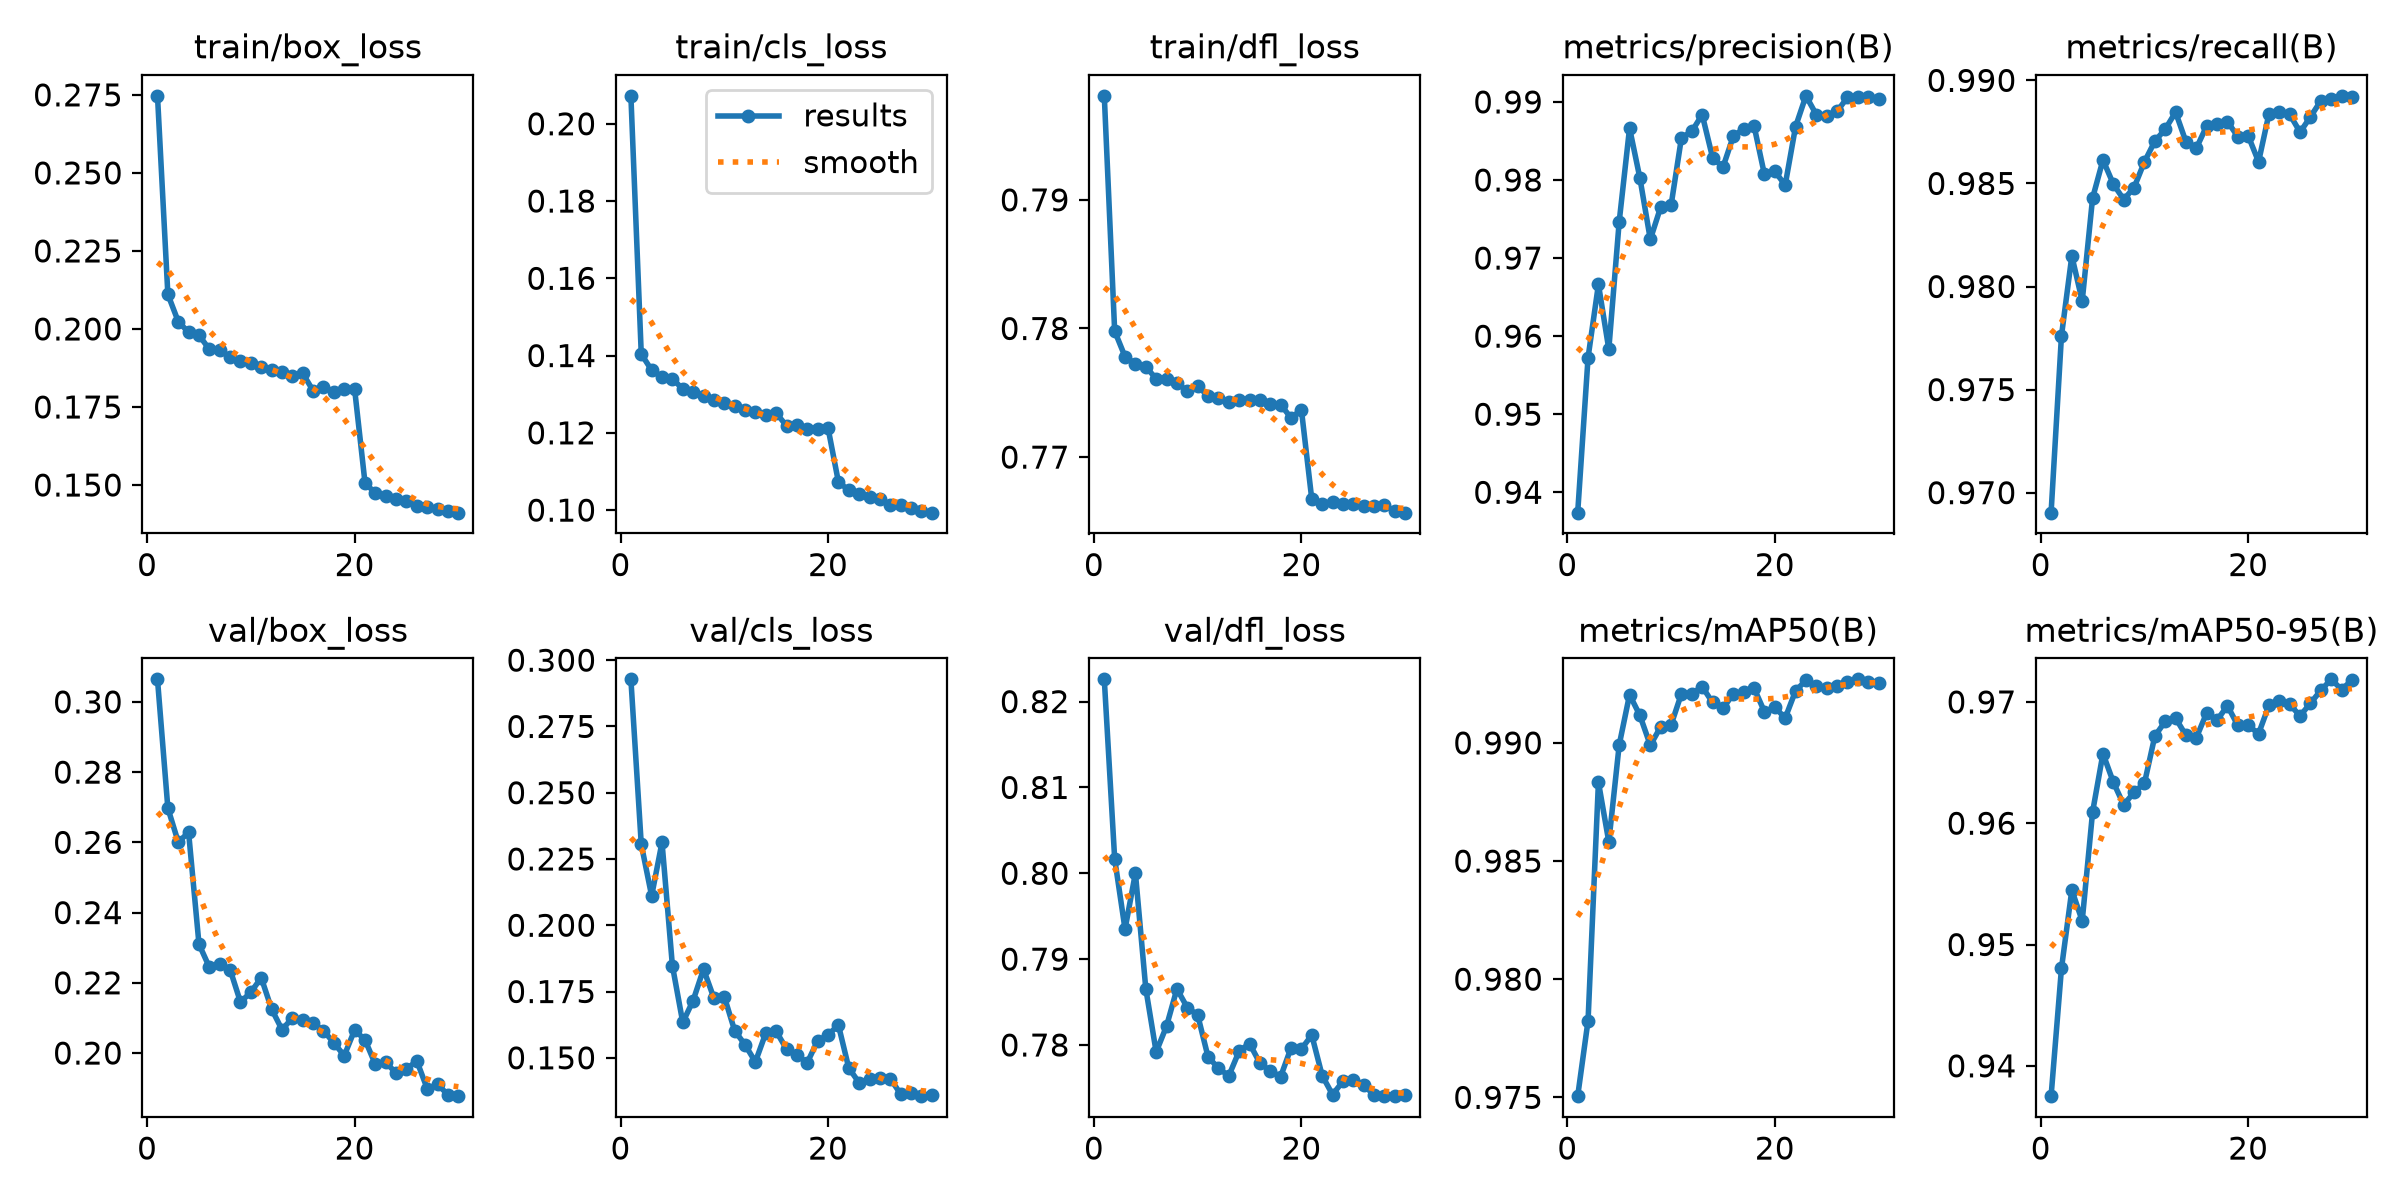

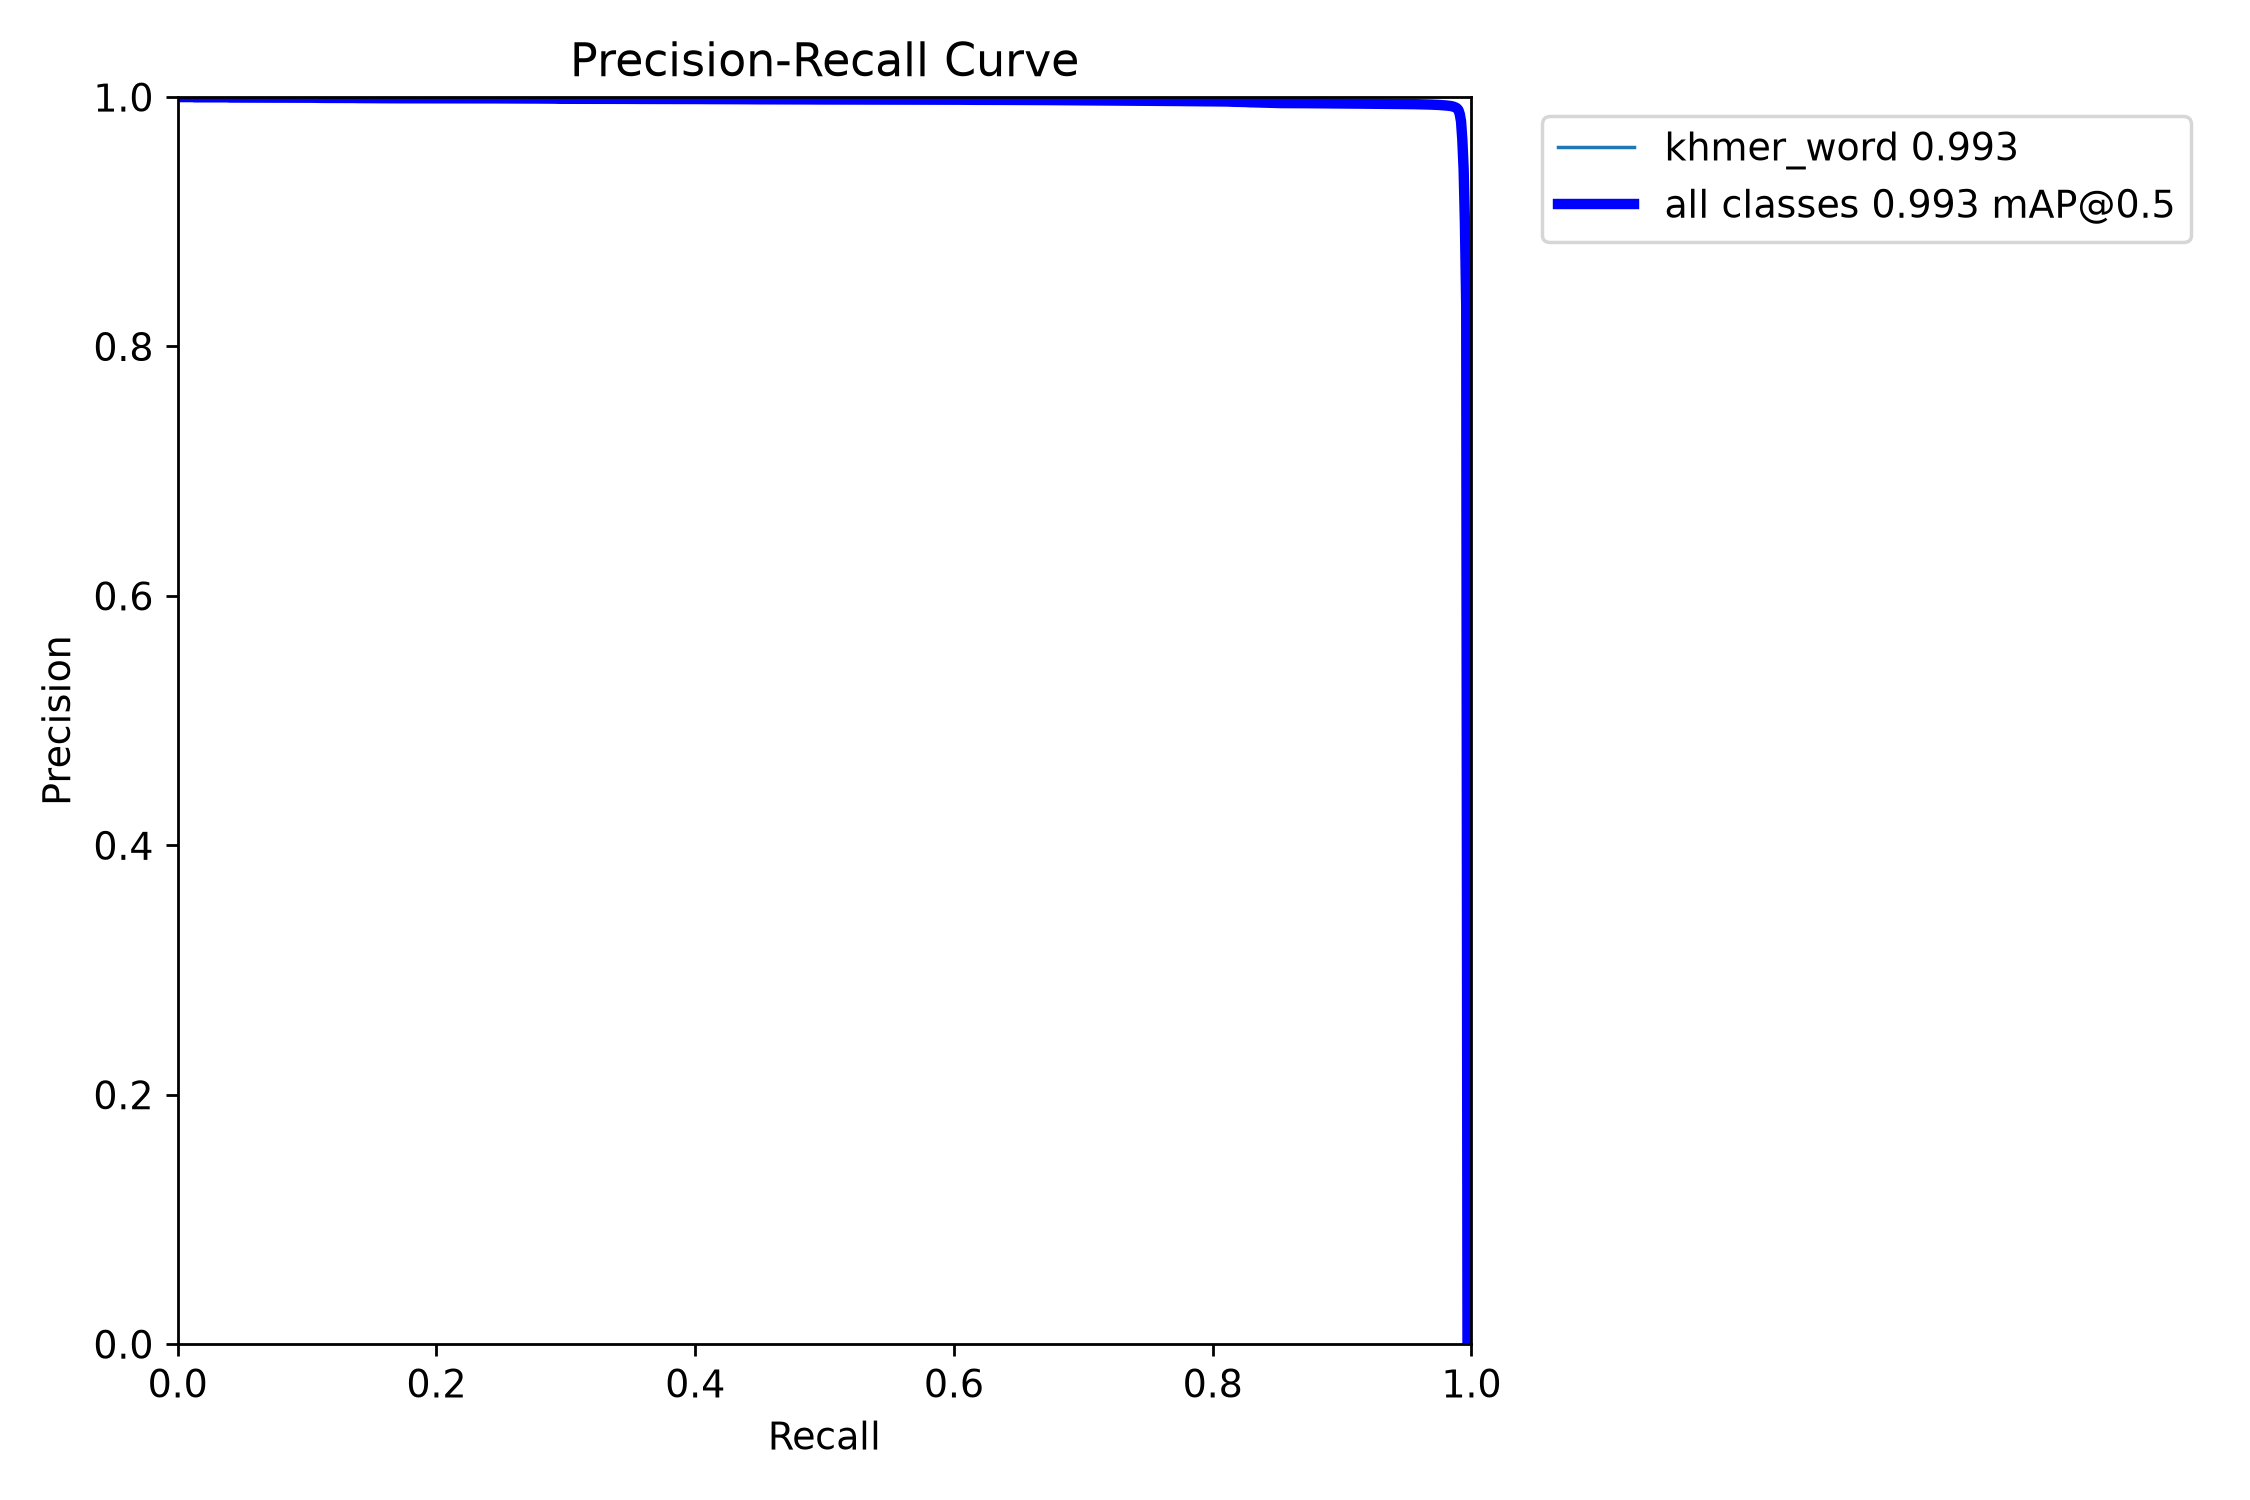

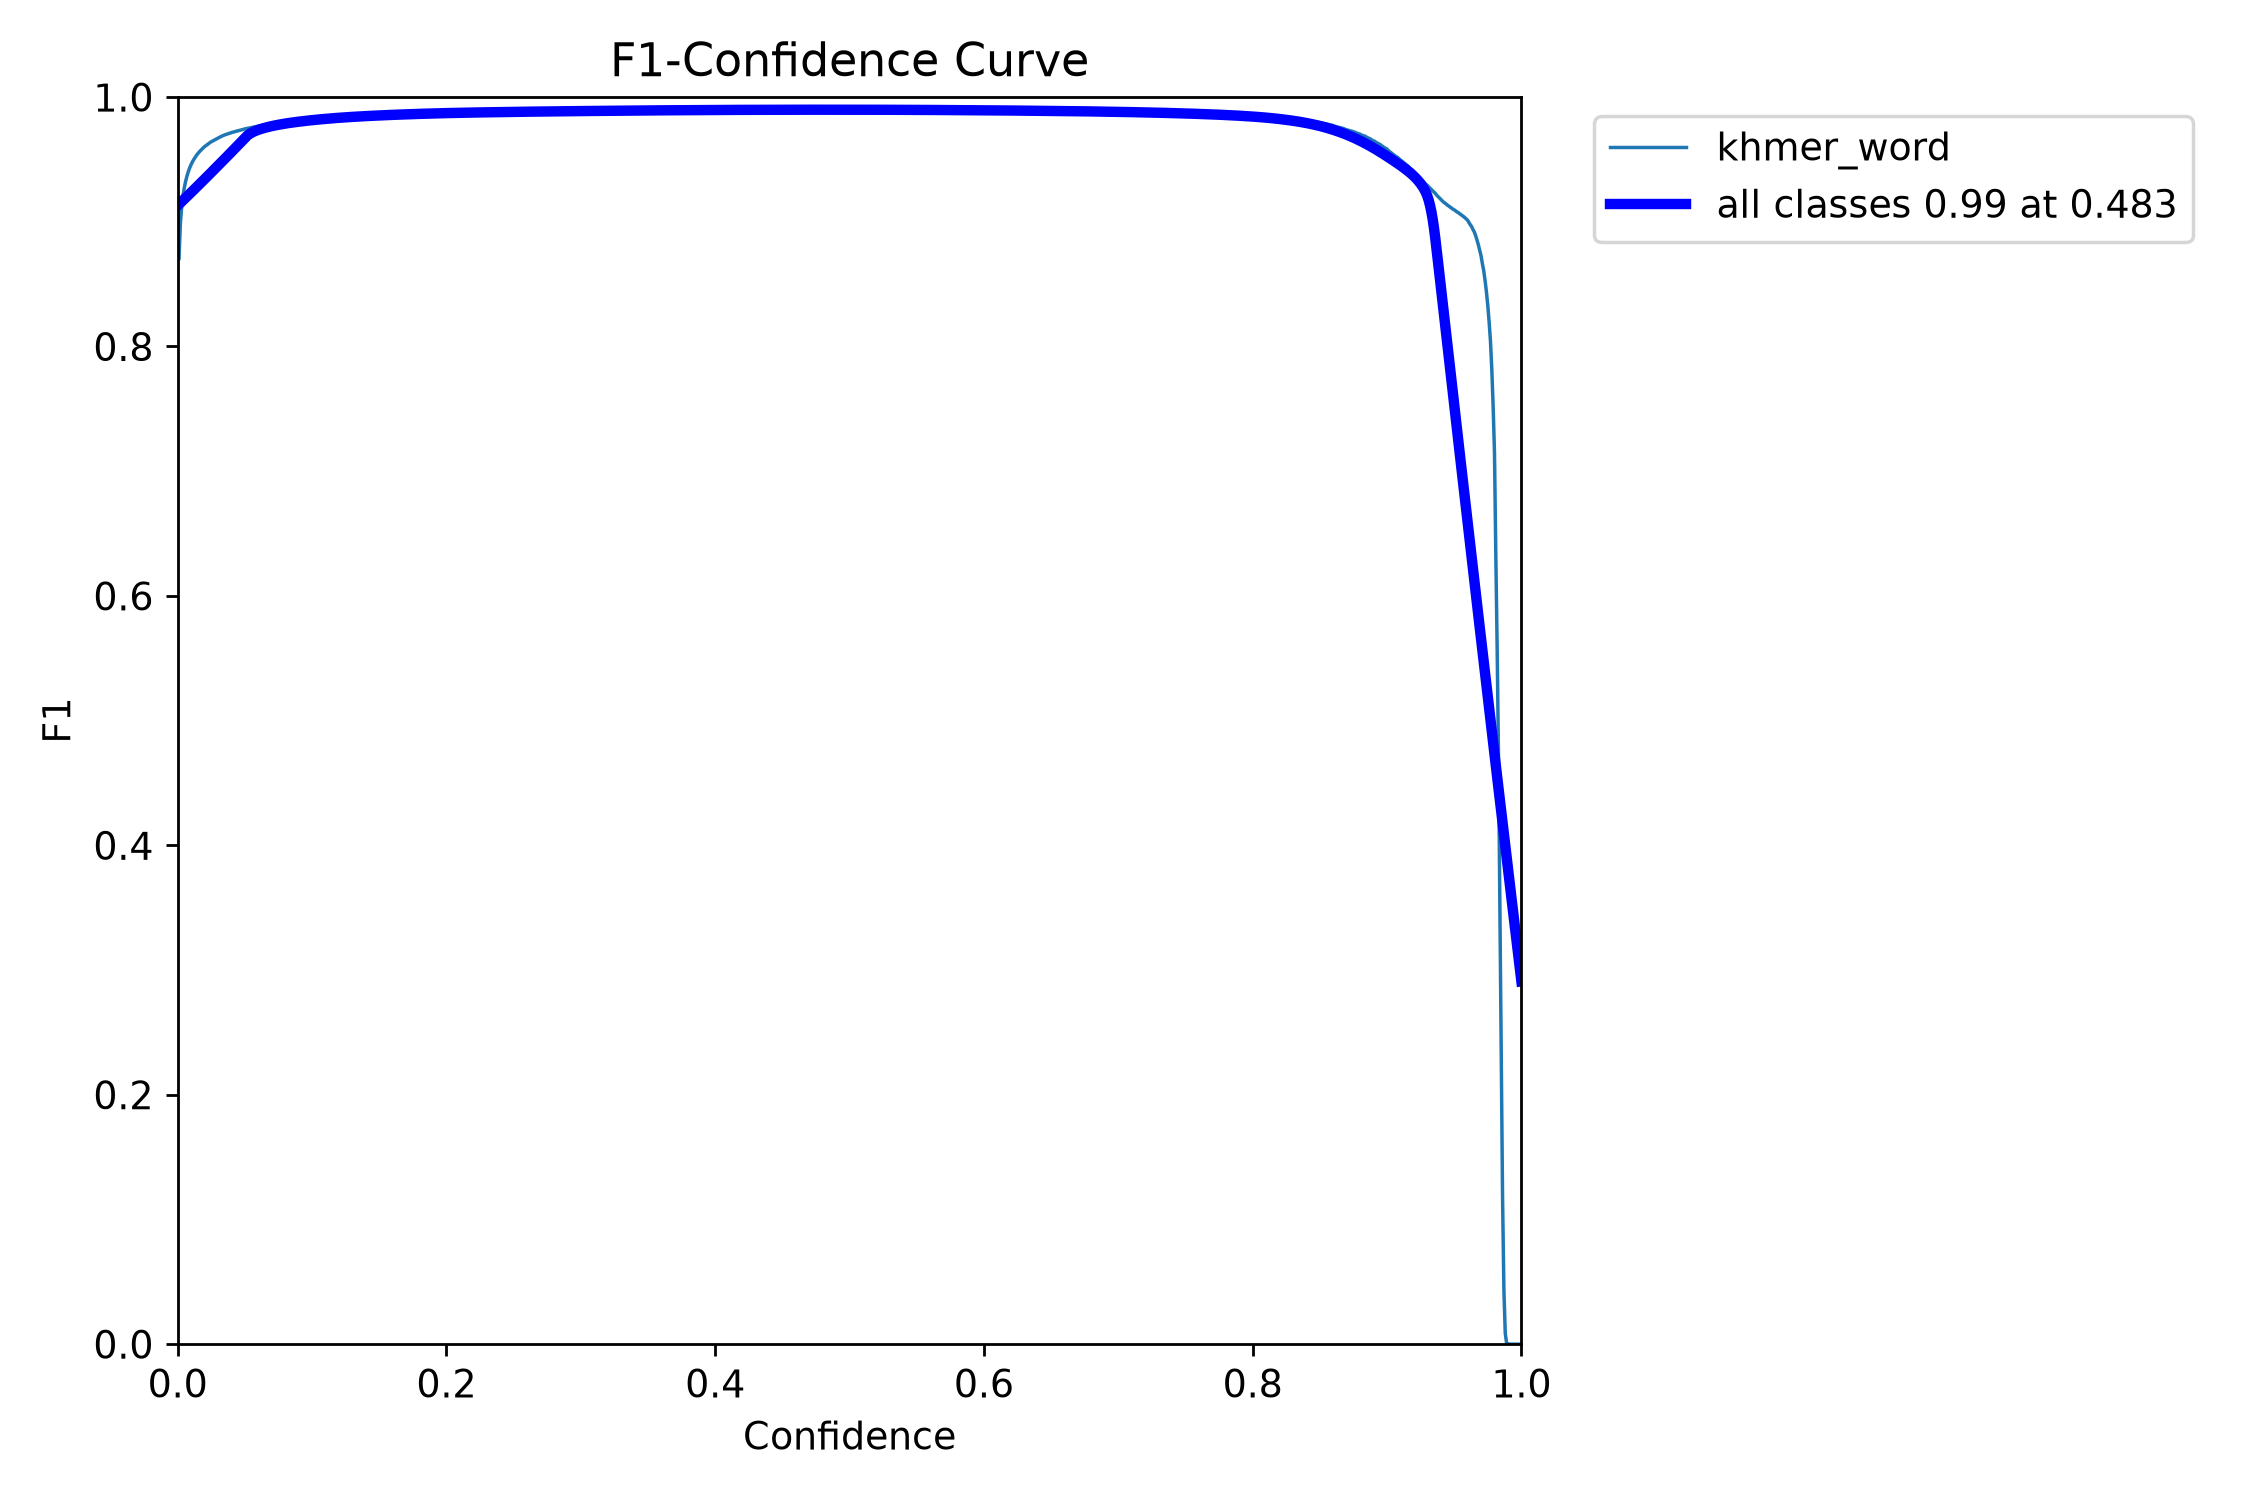

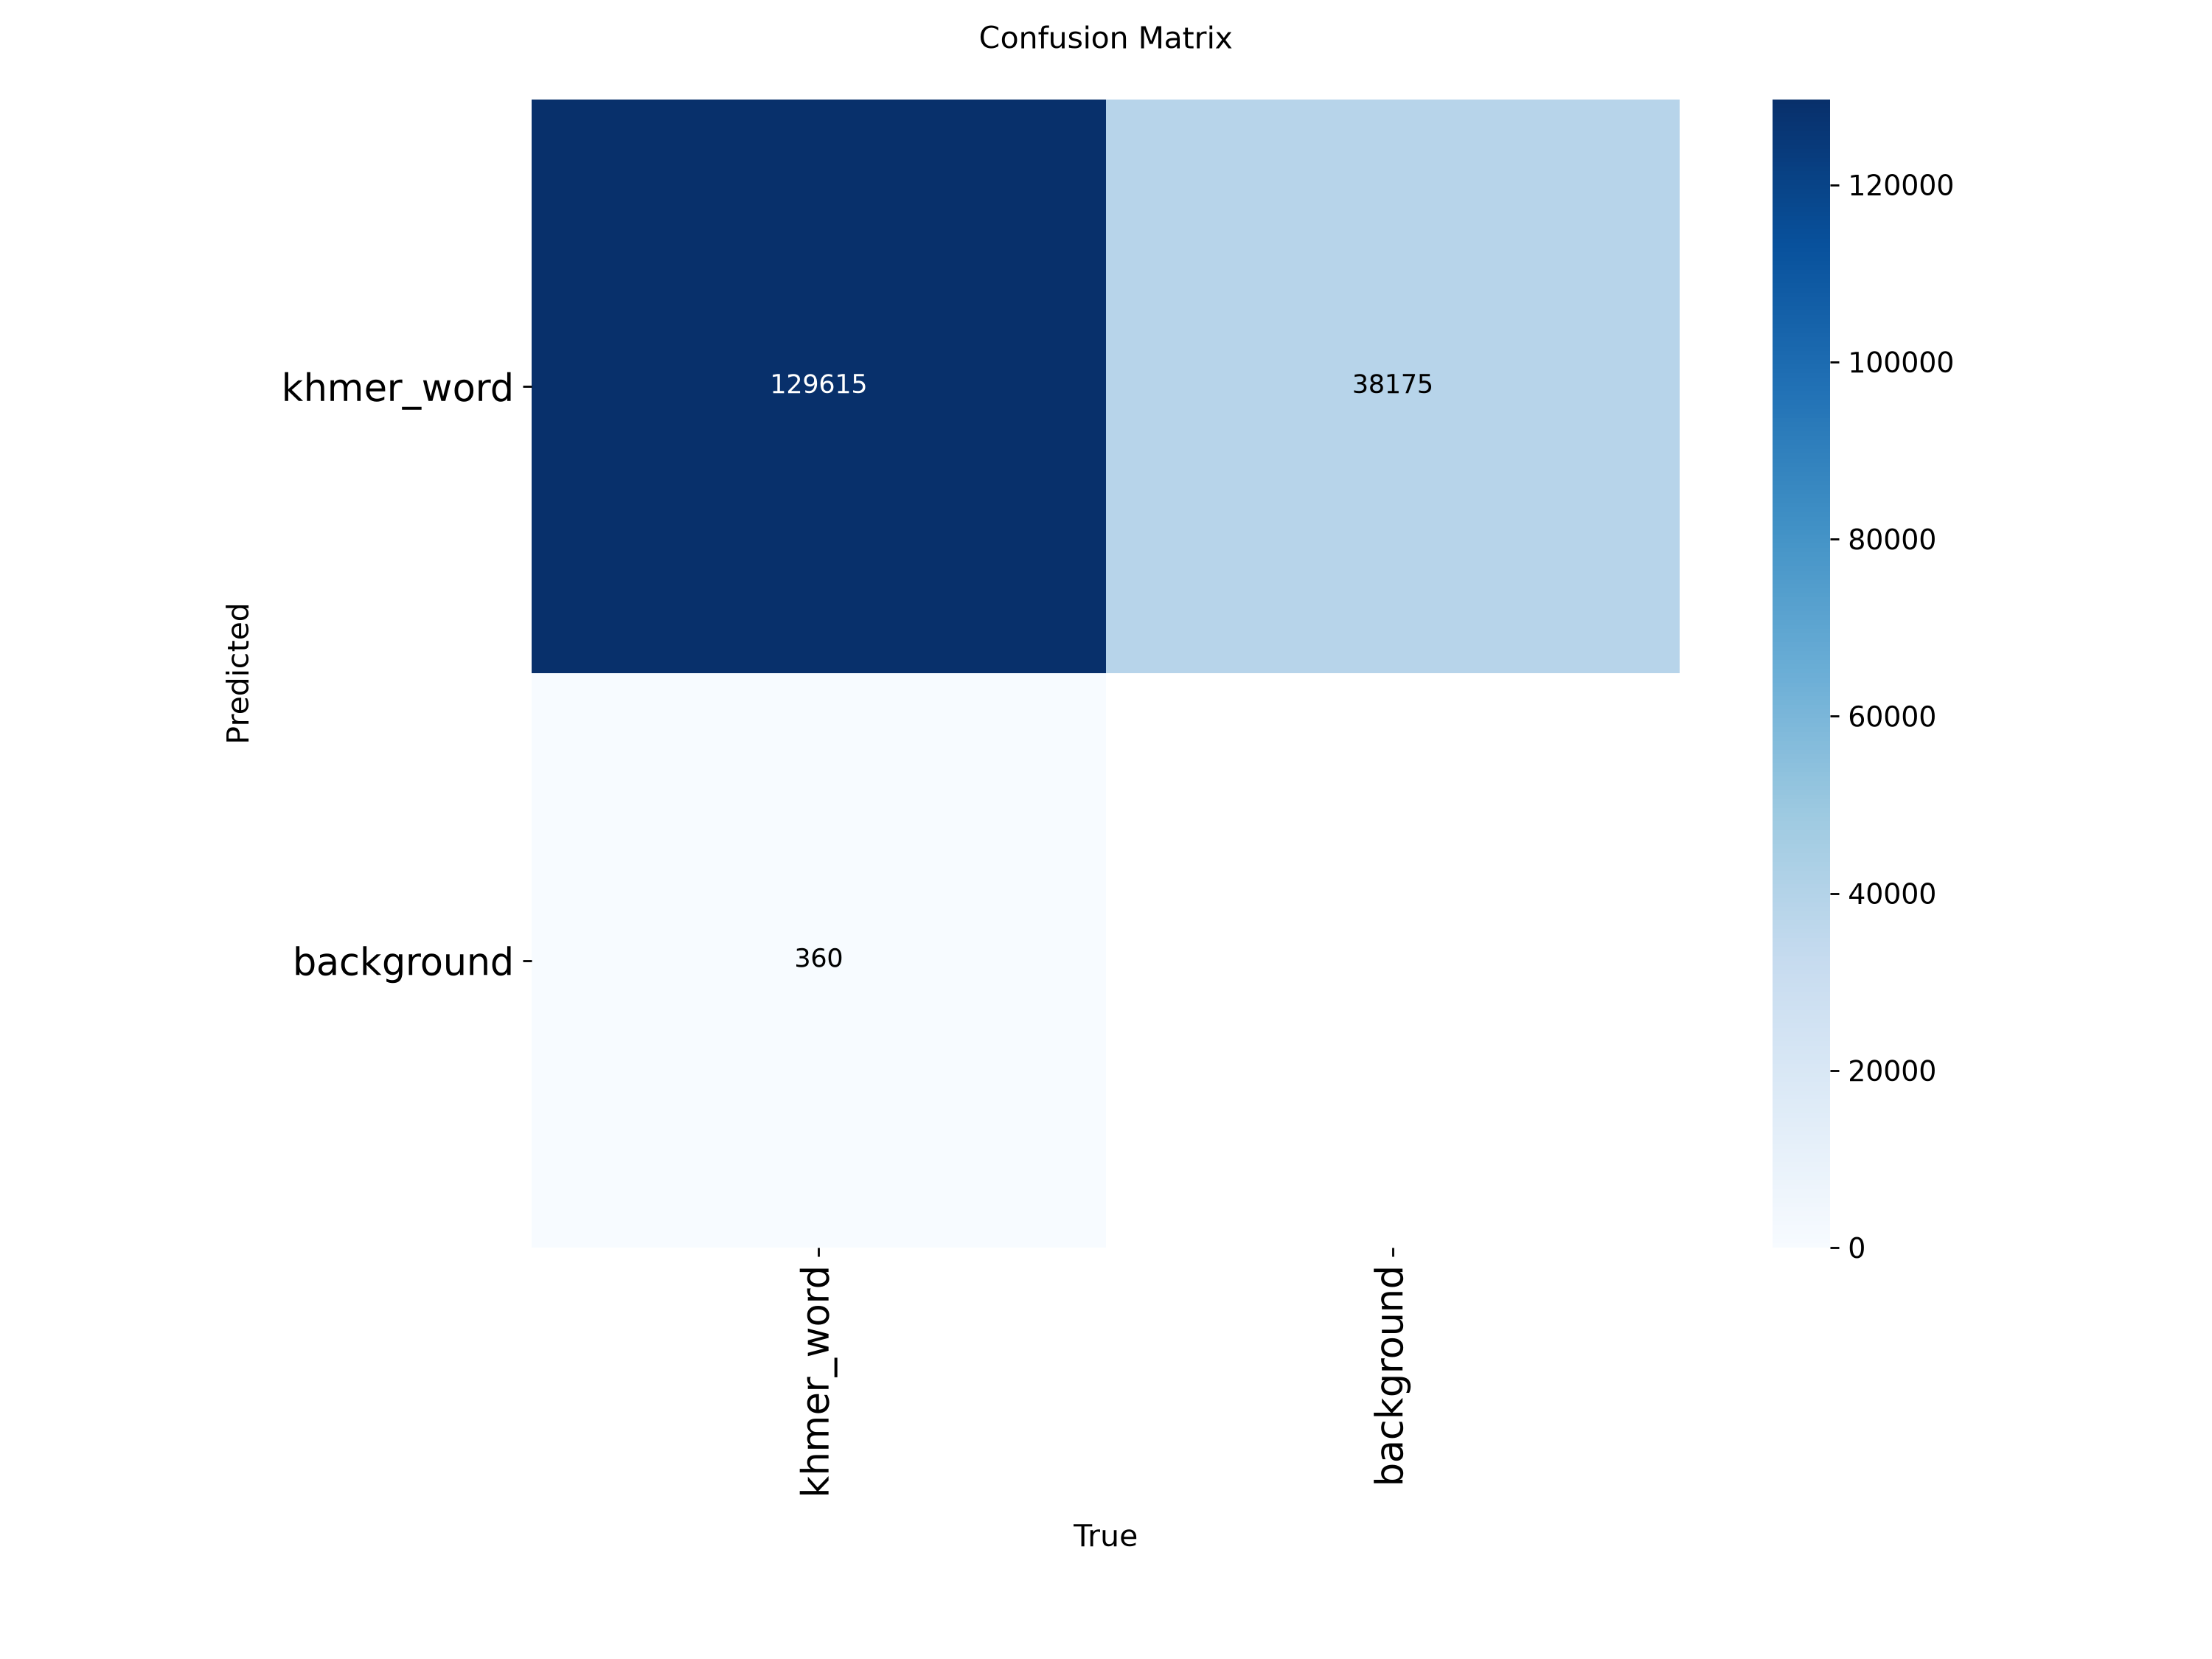

In [8]:
from IPython.display import Image, display
for f in ['results.png', 'BoxPR_curve.png', 'BoxF1_curve.png', 'confusion_matrix.png']:
    display(Image(str(RUN/f), width=800))

## Predict on a few real test pages


0: 640x640 57 khmer_words, 11.9ms
1: 640x640 68 khmer_words, 11.9ms
2: 640x640 65 khmer_words, 11.9ms
Speed: 1.5ms preprocess, 11.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /home/vila/runs/detect/runs/predict_v2


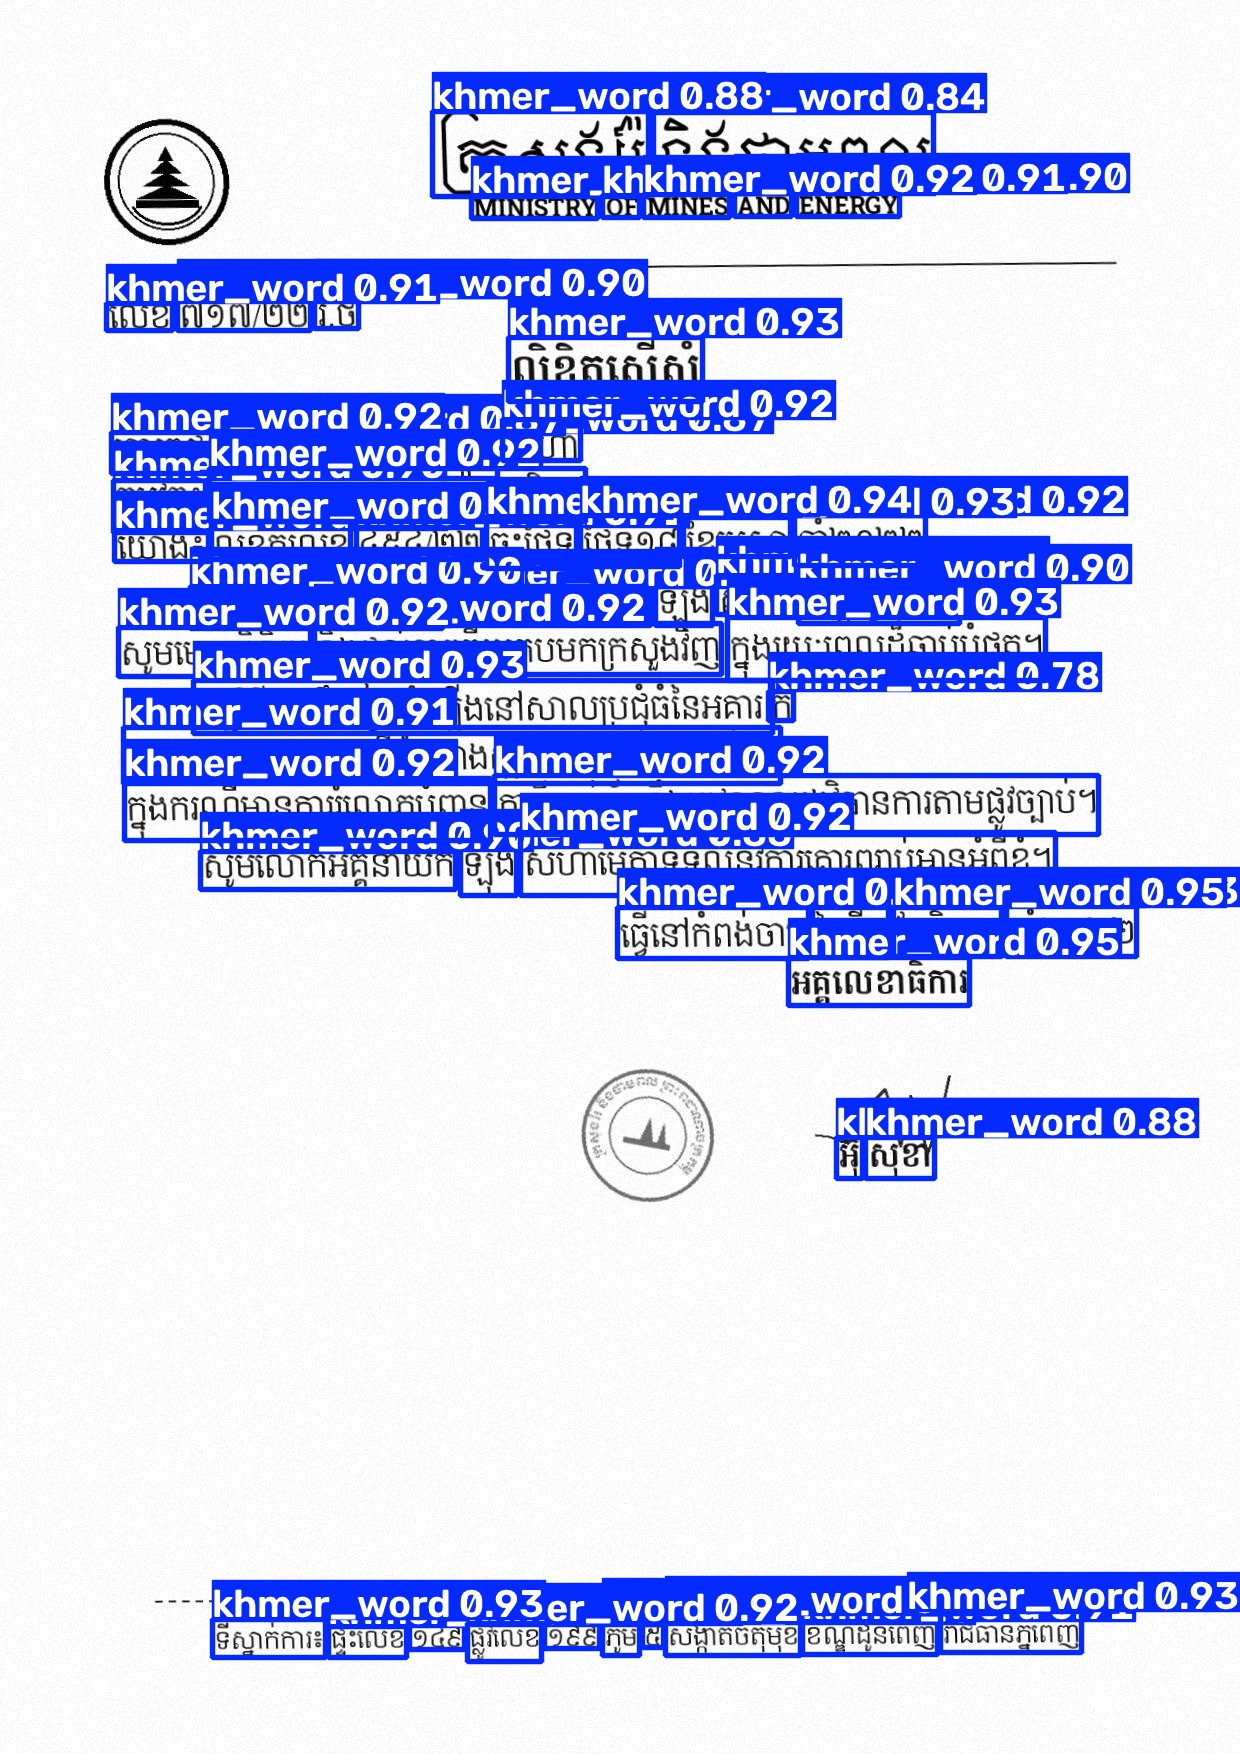

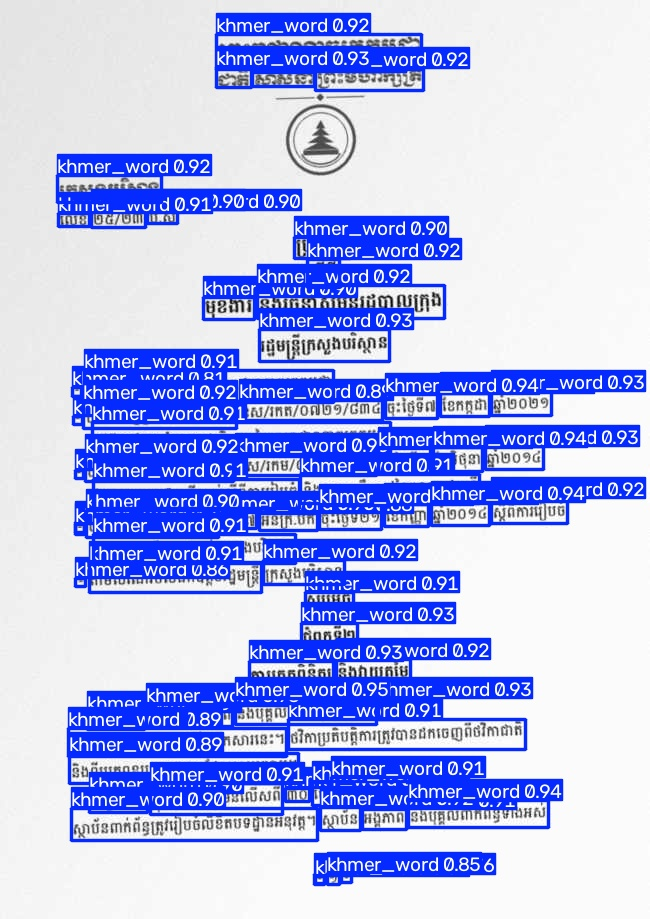

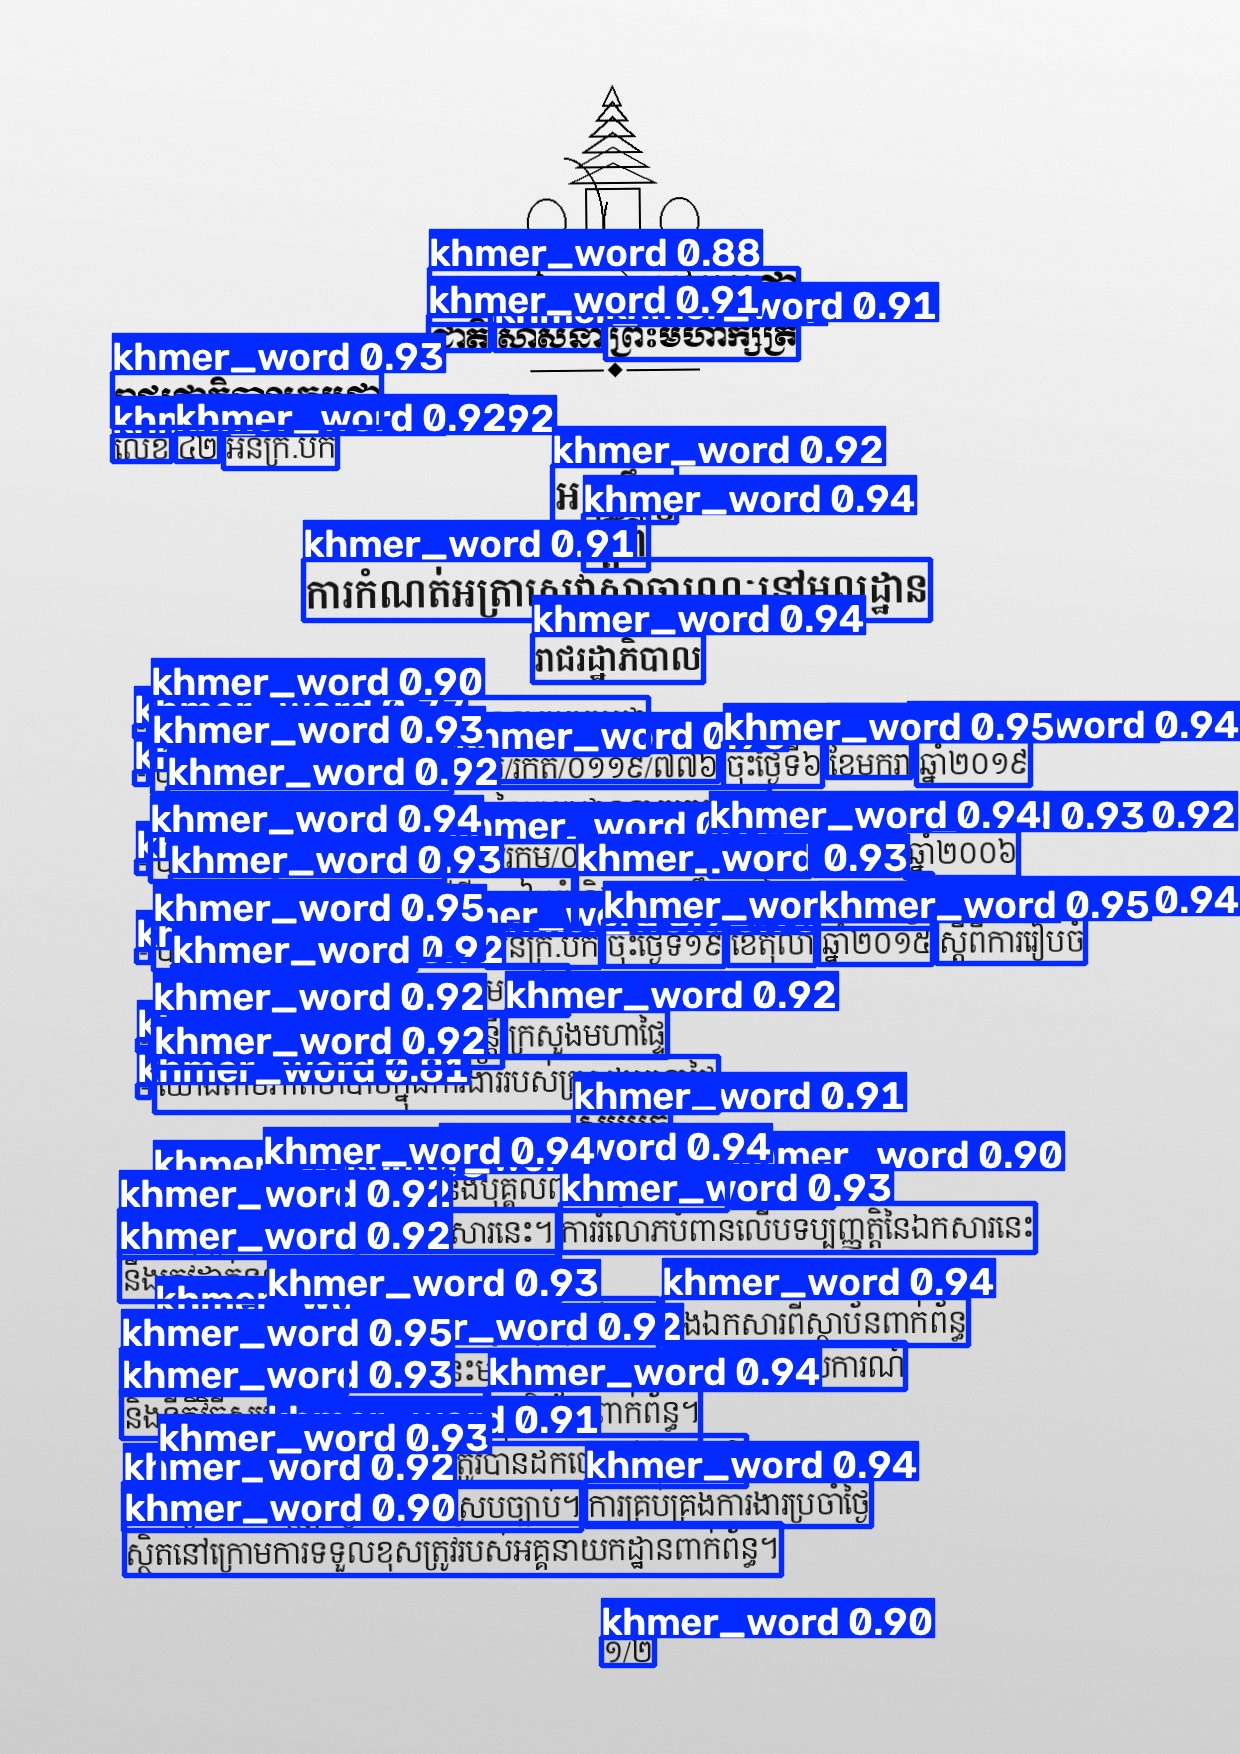

In [9]:
best = YOLO(BEST)
imgs = sorted((REAL['test']/'images'/'test').glob('*'))[:3]
for r in best.predict(imgs, imgsz=IMGSZ, conf=0.25, save=True, project='runs', name='predict_v2', exist_ok=True):
    display(Image(str(Path(r.save_dir)/Path(r.path).name), width=700))

## Export weights
On the laptop: `python scripts/pull_weights.py` (edit its folder to `khmer_word_det_v2` for these weights).

In [10]:
print(BEST, LAST)

/home/vila/khmer-models/khmer_word_det_v2/weights/best.pt /home/vila/khmer-models/khmer_word_det_v2/weights/last.pt
